<a href="https://colab.research.google.com/github/Mansi772/cancer-type-classification/blob/main/cancer_type_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

train = pd.read_csv("data_set_ALL_AML_train.csv")
test = pd.read_csv("data_set_ALL_AML_independent.csv")
labels = pd.read_csv("actual.csv")

def clean(df):
    df = df.drop(columns=["Gene Description", "Gene Accession Number"])
    df = df[[c for c in df.columns if not c.startswith("call")]]
    df = df.T.astype(float)
    df.index = df.index.astype(int)
    return df.sort_index()

X_train = clean(train)
X_test = clean(test)

y = labels.set_index("patient")["cancer"]
y_train = y.loc[X_train.index]
y_test = y.loc[X_test.index]

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(38, 7129) (34, 7129)
cancer
ALL    27
AML    11
Name: count, dtype: int64
cancer
ALL    20
AML    14
Name: count, dtype: int64


In [4]:
print("Train:", X_train.shape, y_train.shape, "Test:", X_test.shape)
print("Missing values:", X_train.isnull().sum().sum())
print(y_train.value_counts())
print(y_test.value_counts())
X_train.iloc[:5, :5]

Train: (38, 7129) (38,) Test: (34, 7129)
Missing values: 0
cancer
ALL    27
AML    11
Name: count, dtype: int64
cancer
ALL    20
AML    14
Name: count, dtype: int64


,0,1,2,3,4
1,-214.0,-153.0,-58.0,88.0,-295.0
2,-139.0,-73.0,-1.0,283.0,-264.0
3,-76.0,-49.0,-307.0,309.0,-376.0
4,-135.0,-114.0,265.0,12.0,-419.0
5,-106.0,-125.0,-76.0,168.0,-230.0


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC()),
}

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5)
    print(f"{name}: {scores.mean():.3f} +/- {scores.std():.3f}")

Logistic Regression: 0.946 +/- 0.066
Random Forest: 0.896 +/- 0.095
SVM: 0.711 +/- 0.046


              precision    recall  f1-score   support

         ALL       0.77      1.00      0.87        20
         AML       1.00      0.57      0.73        14

    accuracy                           0.82        34
   macro avg       0.88      0.79      0.80        34
weighted avg       0.86      0.82      0.81        34



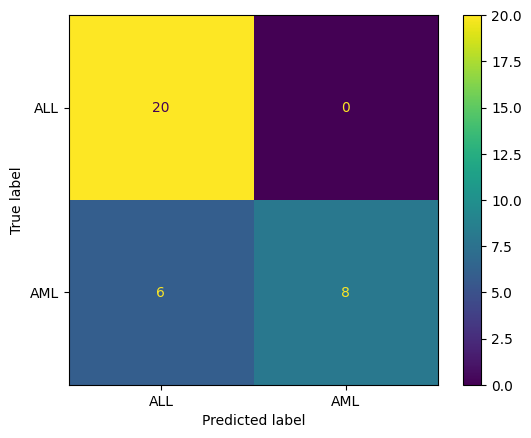

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = models["Logistic Regression"]
best.fit(X_train, y_train)
pred = best.predict(X_test)

print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

In [7]:
coefs = best.named_steps["logisticregression"].coef_[0]
top = np.argsort(np.abs(coefs))[::-1][:15]

genes = train[["Gene Description", "Gene Accession Number"]].iloc[top].copy()
genes["coefficient"] = coefs[top]
genes

,Gene Description,Gene Accession Number,coefficient
4498,CHRNA7 Cholinergic receptor; nicotinic; alpha ...,X70297_at,0.019029
5038,LEPR Leptin receptor,Y12670_at,0.017449
4051,Catalase (EC 1.11.1.6) 5'flank and exon 1 mapp...,X04085_rna1_at,0.017021
1833,CD33 CD33 antigen (differentiation antigen),M23197_at,0.016931
2401,Azurocidin gene,M96326_rna1_at,0.016838
460,Liver mRNA for interferon-gamma inducing facto...,D49950_at,0.016783
3319,Leukotriene C4 synthase (LTC4S) gene,U50136_rna1_at,0.016534
3846,GB DEF = Homeodomain protein HoxA9 mRNA,U82759_at,0.016518
6676,HOX 2.2 gene extracted from Human Hox2.2 gene ...,X58431_rna2_s_at,0.015965
4846,Zyxin,X95735_at,0.015690
